In [7]:
import pandas as pd

df = pd.read_csv(r"C:\Users\kraus\Desktop\Ironhack\Week 5\Labs\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [8]:
category_counts = df['category'].value_counts()
category_counts.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [9]:
# How many total rows are we working with vs. how many are "Sports & Outdoors"?
df.shape[0]
(df['category'] == 'Sports & Outdoors').sum()

# Peek at a random sample of Sports & Outdoors rows — do the titles actually look like sporting goods?
df[df['category'] == 'Sports & Outdoors']['title'].sample(15)

457278     Generisch Raincoat Men's Lightweight Outdoor R...
1209328                   Giro Men's Espada Boa Cycling Shoe
518580     GEMYSE Boy's Mountain Waterproof Ski Jacket Wi...
928333     Equitack Adults Childs Jodhpurs Boots Horse Le...
1458743    Men's Lapel Polo Shirt T-Shirt for Mazda Print...
950267     NOAGENJT Hiking T Shirts for Men Funny Shirts ...
539909                               Desigual Girl's Sweater
888944     INOOMP Gym Cable 1 Set exercise ropes training...
737539     Golf rangefinder with Slope, 300 Pro Range Fin...
1842918    MULOUTSPO Golf Swing Training Aid Golf Arm Ban...
1530939    MXYKJO Heated Vest for Women, Winter Heated Ve...
2035142            Joma Short Third Atalanta Bergame 2022/23
1214413    GZDD Fashion Racing Road Bike Cycling Shoes Ul...
1218826    Scooter Replacement Accessory, Professional Mo...
980035     Azeeda 'Coffee & Croissant' Kid's Sweatshirt/J...
Name: title, dtype: object

In [10]:
df['category'].nunique()

296

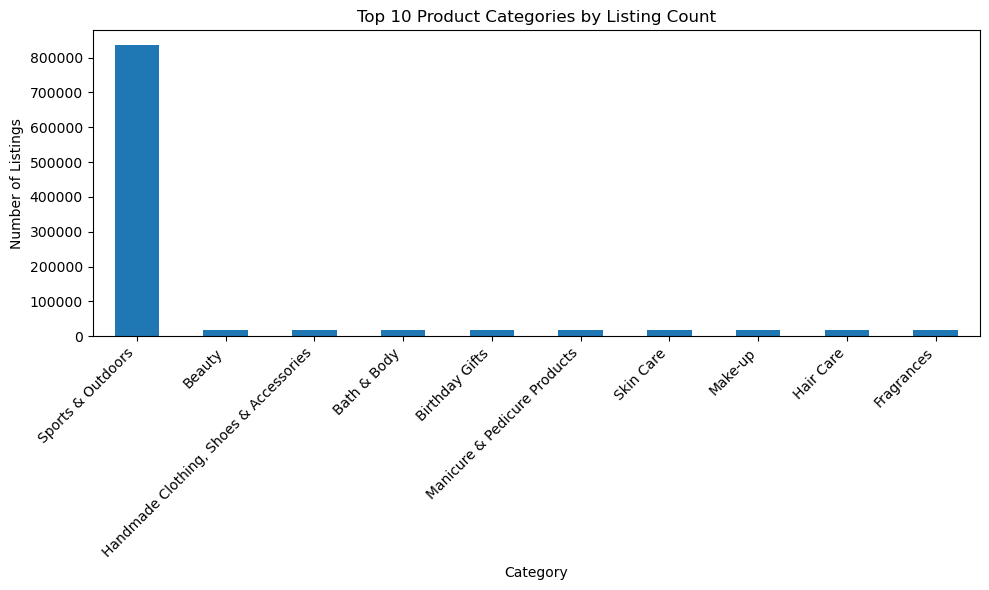

In [11]:
import matplotlib.pyplot as plt

top10 = df['category'].value_counts().head(10)

plt.figure(figsize=(10,6))
top10.plot(kind='bar')
plt.title('Top 10 Product Categories by Listing Count')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

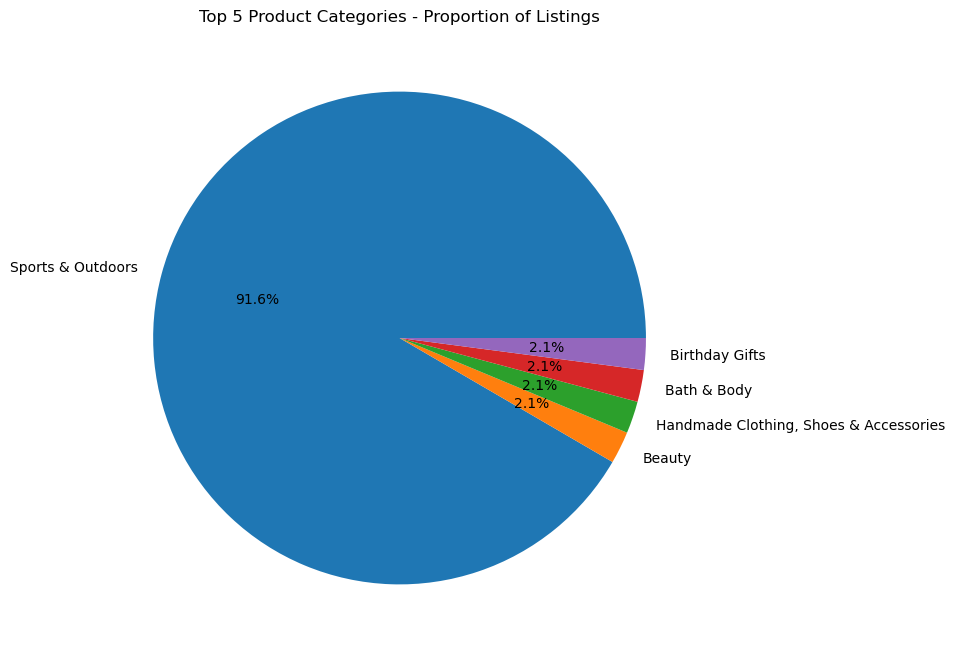

In [12]:
top5 = df['category'].value_counts().head(5)

plt.figure(figsize=(8,8))
plt.pie(top5, labels=top5.index, autopct='%1.1f%%')
plt.title('Top 5 Product Categories - Proportion of Listings')
plt.show()

In [13]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(mean_price, median_price, mode_price)

89.24380943923661 19.09 9.99


In [14]:
variance_price = df['price'].var()
std_price = df['price'].std()
range_price = df['price'].max() - df['price'].min()
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr_price = q3 - q1

print(variance_price, std_price, range_price, iqr_price)

119445.48532256528 345.60886175352226 100000.0 36.0


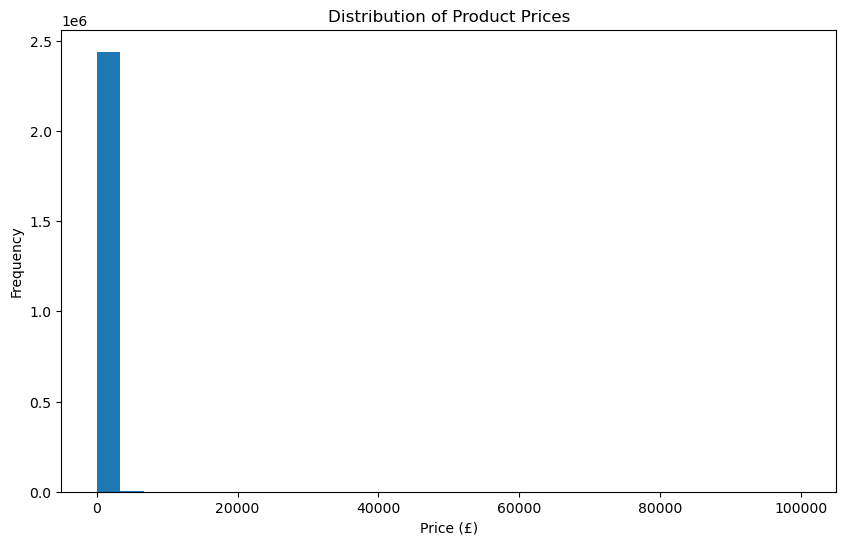

In [15]:
plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=30)
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

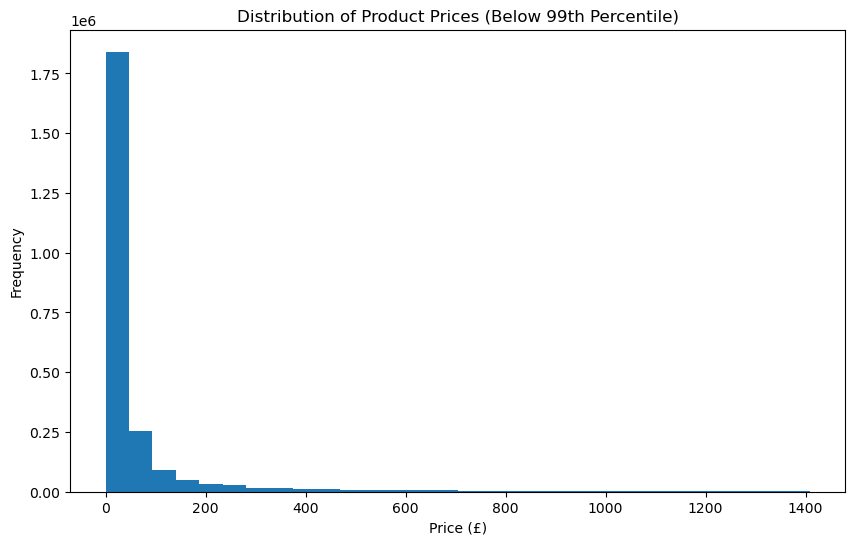

In [16]:
price_99 = df['price'].quantile(0.99)
filtered_prices = df[df['price'] <= price_99]['price']

plt.figure(figsize=(10,6))
plt.hist(filtered_prices, bins=30)
plt.title('Distribution of Product Prices (Below 99th Percentile)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

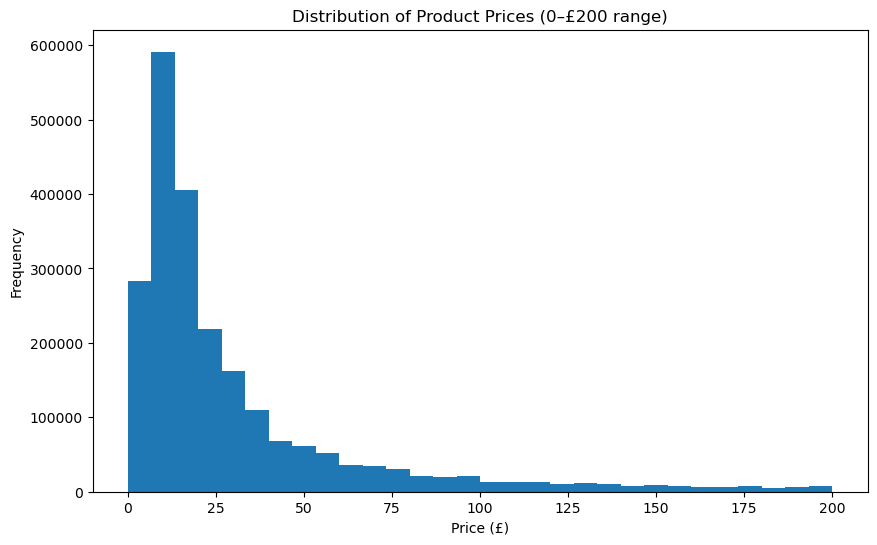

In [17]:
plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=30, range=(0, 200))
plt.title('Distribution of Product Prices (0–£200 range)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()

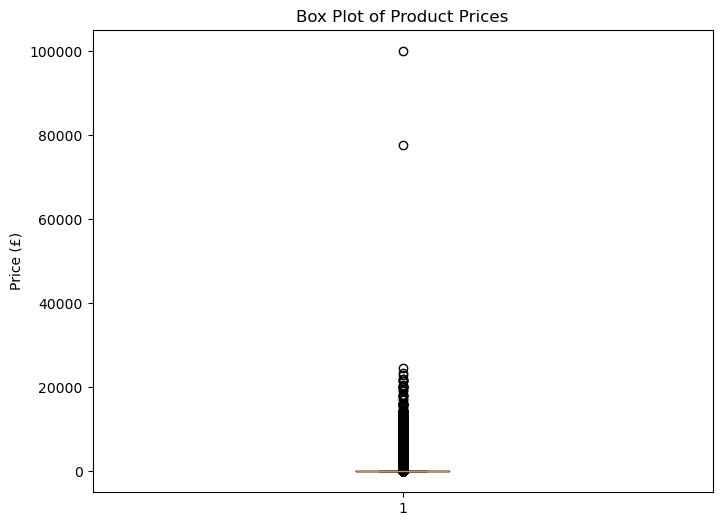

In [18]:
plt.figure(figsize=(8,6))
plt.boxplot(df['price'])
plt.title('Box Plot of Product Prices')
plt.ylabel('Price (£)')
plt.show()

In [19]:
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]

print(mean_stars, median_stars, mode_stars)

2.152836472966066 0.0 0.0


In [20]:
from scipy.stats import skew, kurtosis

skew_stars = skew(df['stars'].dropna())
kurt_stars = kurtosis(df['stars'].dropna())

print(skew_stars, kurt_stars)

0.08120730776283251 -1.9260046425498398


In [21]:
(df['stars'] == 0).sum()
df['stars'].value_counts().head(10)

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
Name: count, dtype: int64

In [22]:
rated_only = df[df['stars'] > 0]['stars']

mean_stars = rated_only.mean()
median_stars = rated_only.median()
mode_stars = rated_only.mode()[0]

print(mean_stars, median_stars, mode_stars)

skew_stars = skew(rated_only.dropna())
kurt_stars = kurtosis(rated_only.dropna())
print(skew_stars, kurt_stars)

4.319160762226911 4.4 4.5
-2.3795651817332555 9.781892609238655


In [ ]:
# Raw stars data initially looked odd — median and mode both at 0, near-flat skewness, negative kurtosis
# Investigation revealed 50% of products have stars = 0, almost certainly representing unrated products rather than genuine 0-star ratings
# After filtering to only rated products, the distribution reveals what you'd expect from real customer rating behavior: strongly left-skewed, heavily clustered at 4-5 stars, sharp peak (high kurtosis)
# Actionable insight: the raw dataset conflates "no reviews" with "0-star reviews"... any future analysis using this column should filter zeros first, and Amazon UK's product catalog shows the classic reviewer-selection-bias pattern (satisfied customers rate; unremarkable experiences don't generate reviews)

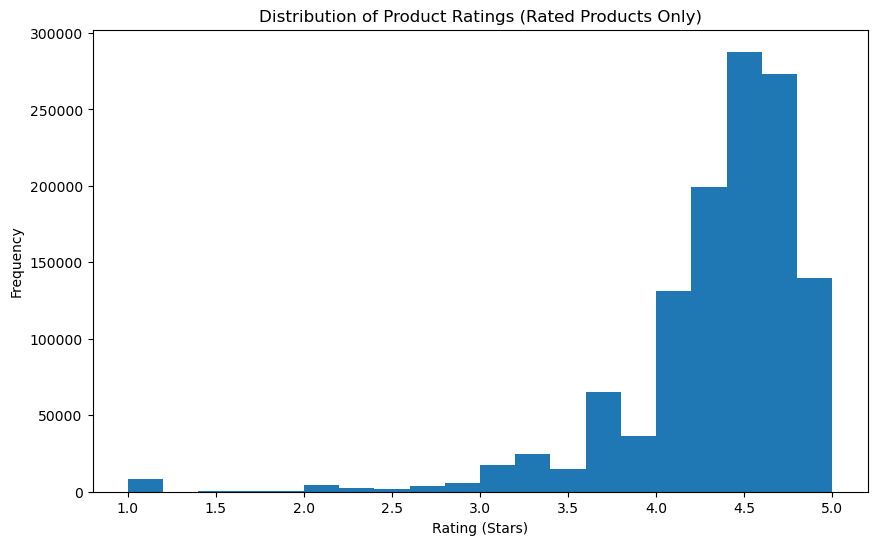

In [23]:
plt.figure(figsize=(10,6))
plt.hist(rated_only, bins=20)
plt.title('Distribution of Product Ratings (Rated Products Only)')
plt.xlabel('Rating (Stars)')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Part 1: Sports & Outdoors dominates listings, likely reflecting a broad umbrella category rather than true market concentration, visualized correctly by subsetting to top categories once you reasoned out why the full category chart wouldn't work
# Part 2: Prices are strongly right-skewed, mean inflated far above median by extreme high-end outliers, IQR reveals the real "typical" spread is much tighter than std dev suggests, a genuine data-quality-aware pricing analysis
# Part 3: Ratings appeared oddly distributed at first, investigation revealed 50% zero-inflation from unrated products, and once filtered, ratings show the expected left-skewed, highly-clustered-near-5-stars pattern consistent with real reviewer behavior